# 第 6 课 · 市场份额反演与 IV/GMM

商店在多个地区销售五款饮料。每个地区有自己的价格、商品特征和销量，研究者只有产品—市场层面的数据。经理观察到本地消费者的购买意愿，需求旺盛时可能提价。我们的任务是从市场份额和成本变动中估计需求，再解释为什么一条拟合很好的需求曲线仍可能给出错误的提价预测。

建议安排 **两次各 75 分钟**。第一讲推导份额反演和工具变量估计，第二讲编写市场聚类 GMM、核对推断并修改数据生成过程。课后练习约 4–6 小时。先完成[第 4 课](04-price-endogeneity.ipynb)，复习矩阵求逆、最小二乘和渐近正态近似。全课仅使用 NumPy、SciPy 和 Matplotlib。

## 1. 从产品份额反推出平均效用

设市场为 $t$，产品为 $j$。每位顾客可以购买一款，或不购买。产品的平均效用为 $\delta_{jt}$，外部选项的平均效用归一化为零。沿用[第 3 课](03-multinomial-logit.ipynb)的独立同分布标准极值误差，模型预测的市场份额为

$$
s_{jt}=\frac{\exp(\delta_{jt})}{1+\sum_{k\in\mathcal J_t}\exp(\delta_{kt})},
\qquad
s_{0t}=\frac{1}{1+\sum_{k\in\mathcal J_t}\exp(\delta_{kt})}.
$$

两式相除得到 **Berry 反演**。共同分母消去后，每款产品的平均效用由其相对外部选项的份额决定。

$$
y_{jt}\equiv\log(s_{jt})-\log(s_{0t})
=\delta_{jt}=a+x_{jt}\beta_x+p_{jt}\beta_p+\xi_{jt}.
$$

应用中若市场规模是 $M_t$、产品销量是 $q_{jt}$，应使用 $s_{jt}=q_{jt}/M_t$ 和 $s_{0t}=1-\sum_j q_{jt}/M_t$。把各产品销量除以店内总销量，会把“不买”从分母排除。此时外部份额为零，反演也无法计算。零销量、份额精度和市场规模的口径需要结合数据生成过程处理。本实验直接生成总体模型份额，以集中讨论价格内生性。 [Berry（1994）](https://doi.org/10.2307/2555829)

## 2. 模拟报价、品质和份额

在每个市场生成五款产品，每款有可观测特征 $x_{jt}$ 和不可观测品质 $\xi_{jt}$。不可观测品质含市场共同冲击，因而同一市场内的矩条件可以相关。商店看到 $\xi_{jt}$ 后定价，成本冲击 $z_{1,jt}$ 和 $z_{2,jt}$ 也会传导到价格。

$$
\begin{aligned}
\xi_{jt}&=0.55\eta_t+0.55u_{jt},\\
z_{1,jt}&=0.60b_t+0.80e_{jt},\\
p_{jt}&=5+0.45x_{jt}+0.75\xi_{jt}
     +\kappa(0.80z_{1,jt}+0.55z_{2,jt})+0.35v_{jt}.
\end{aligned}
$$

各基础冲击和 $x$ 分别独立抽自标准正态分布，需求冲击 $\eta_t$ 与成本冲击 $b_t$ 都在同一市场的产品间共享，两者互相独立。基准的成本传导强度 $\kappa=1$。在这个模拟设定中，两项成本冲击独立于 $\xi$，也没有直接进入效用。用于拟合的 $X$ 保存常数、产品特征和价格，$Z$ 保存常数、产品特征和两个被排除的成本工具。真参数仅用于生成数据和核对结果。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from scipy.stats import chi2

true_theta = np.array([4.45, 0.65, -0.85])
parameter_names = ("Intercept", "Product characteristic", "Price")


def simulate_markets(seed=607, markets=180, products=5, cost_strength=1.0,
                     direct_cost_effect=0.0):
    rng = np.random.default_rng(seed)
    shape = (markets, products)
    x, local_cost, z2, local_quality, price_noise = rng.normal(size=(5, *shape))
    market_quality, market_cost = rng.normal(size=(2, markets, 1))
    z1 = 0.60 * market_cost + 0.80 * local_cost
    xi = 0.55 * market_quality + 0.55 * local_quality + direct_cost_effect * z2
    price = 5 + 0.45 * x + 0.75 * xi + cost_strength * (0.80 * z1 + 0.55 * z2)
    price += 0.35 * price_noise

    intercept, beta_x, beta_price = true_theta
    delta = intercept + beta_x * x + beta_price * price + xi
    utilities = np.column_stack((np.zeros(markets), delta))
    shares = np.exp(utilities - logsumexp(utilities, axis=1, keepdims=True))
    outside, inside = shares[:, 0], shares[:, 1:]
    # 数据中的外部份额来自市场总份额和店内产品份额。
    observed_outside = 1 - inside.sum(axis=1)
    assert np.all(inside > 0) and np.all(observed_outside > 0)
    np.testing.assert_allclose(observed_outside, outside, atol=1e-12)
    y = (np.log(inside) - np.log(observed_outside[:, None])).ravel()
    np.testing.assert_allclose(y, delta.ravel(), atol=1e-11)

    ones = np.ones(markets * products)
    return {
        "y": y,
        "X": np.column_stack((ones, x.ravel(), price.ravel())),
        "Z": np.column_stack((ones, x.ravel(), z1.ravel(), z2.ravel())),
        "market": np.repeat(np.arange(markets), products),
        "inside": inside,
        "outside": observed_outside,
        "xi_true": xi.ravel(),
    }


base = simulate_markets()
y, X, Z = base["y"], base["X"], base["Z"]
print(f"Markets: {len(base['outside'])}, rows: {len(y)}, products per market: {base['inside'].shape[1]}")
print(f"Outside share, min / median / max: {base['outside'].min():.3f} / "
      f"{np.median(base['outside']):.3f} / {base['outside'].max():.3f}")
print(f"Price–latent quality correlation (simulation only): {np.corrcoef(X[:, 2], base['xi_true'])[0, 1]:.3f}")

Markets: 180, rows: 900, products per market: 5
Outside share, min / median / max: 0.027 / 0.118 / 0.328
Price–latent quality correlation (simulation only): 0.467


## 3. 识别依赖什么价格变动？

用 $y=\log(s_j/s_0)$ 作因变量后，OLS 仍要求解释变量与结构误差正交。在本实验中，$\xi$ 同时进入需求和价格，价格的 OLS 系数会把成本导致的价格变动和需求旺盛时的提价混在一起。

令 $\theta=(a,\beta_x,\beta_p)'$，$X_{jt}$ 和 $Z_{jt}$ 都写作列向量。工具变量（instrumental variables，IV）的矩条件为

$$
E[Z_{jt}\xi_{jt}]=0,
\qquad
\xi_{jt}=y_{jt}-X_{jt}'\theta.
$$

- **正交性**要求成本工具与需求误差不相关。这里由模拟的独立抽样给出。
- **排除限制**要求给定控制变量和价格后，成本工具不直接改变需求。若降成本同时改善了消费者感知的品质，排除限制可能失败。
- **秩条件**要求 $E[Z_{jt}X_{jt}']$ 的列秩为 3。在控制 $x$ 后，至少有一项被排除的工具会移动价格。样本矩阵满秩只能说明当前样本可以求解。很弱的价格变动仍可能导致不稳定推断。

下面检查两项工具在控制 $x$ 后的第一阶段系数和部分 $R^2$。由于同一市场的产品共享冲击，显著性检验按市场聚类。

In [2]:
def market_moment_covariance(moment_rows, market):
    # 估计 sqrt(N) 乘以行均值后的协方差，允许同一市场内相关。
    _, group_index = np.unique(market, return_inverse=True)
    sums = np.zeros((group_index.max() + 1, moment_rows.shape[1]))
    np.add.at(sums, group_index, moment_rows)
    return sums.T @ sums / len(moment_rows)


def first_stage(data):
    price, instruments = data["X"][:, 2], data["Z"]
    n = len(price)
    coef = np.linalg.lstsq(instruments, price, rcond=None)[0]
    residual = price - instruments @ coef
    controls = data["X"][:, :2]
    residual_without_iv = price - controls @ np.linalg.lstsq(controls, price, rcond=None)[0]
    partial_r2 = 1 - residual @ residual / (residual_without_iv @ residual_without_iv)

    meat = market_moment_covariance(instruments * residual[:, None], data["market"])
    bread = np.linalg.solve(instruments.T @ instruments / n, np.eye(instruments.shape[1]))
    variance = bread @ meat @ bread.T / n
    q = len(coef) - controls.shape[1]
    excluded = coef[-q:]
    excluded_cov = variance[-q:, -q:]
    wald = excluded @ np.linalg.solve(excluded_cov, excluded)
    return excluded, partial_r2, wald, chi2.sf(wald, q)


cost_coef, partial_r2, first_wald, first_pvalue = first_stage(base)
print(f"Cost shifter coefficients: {cost_coef}")
print(f"Partial R²: {partial_r2:.3f}")
print(f"Market-cluster Wald χ²(2): {first_wald:.2f}, p = {first_pvalue:.3g}")

Cost shifter coefficients: [0.77149292 0.58798245]
Partial R²: 0.633
Market-cluster Wald χ²(2): 1219.54, p = 1.52e-265


第一阶段的 Wald 检验考察两个成本系数是否同时为零。需求方的排除限制要结合制度依据判断，弱工具诊断也有专门的统计量和临界值。

## 4. 从 2SLS 到市场聚类的两步 GMM

用 $N$ 表示产品—市场行数，$K=3$ 为参数个数，$L=4$ 为工具个数。把数据中的行向量堆成 $X\in\mathbb R^{N\times K}$ 和 $Z\in\mathbb R^{N\times L}$。样本矩是 $L$ 维向量，记为

$$
g_N(\theta)=\frac{Z'(y-X\theta)}{N}=q-D\theta,\qquad
q=\frac{Z'y}{N},\quad D=\frac{Z'X}{N}.
$$

因为 $L>K$，通常无法令所有样本矩恰好为零。广义矩估计（generalized method of moments，GMM）给不同方向的矩条件赋权，最小化 $g_N(\theta)'Wg_N(\theta)$。对 $\theta$ 求导得到 $D'W(q-D\hat\theta)=0$，故

$$
\hat\theta(W)=(D'WD)^{-1}D'Wq.
$$

第一步选 $W_1=(Z'Z/N)^{-1}$。此时 $D'W_1D=X'P_ZX/N$，$P_Z=Z(Z'Z)^{-1}Z'$，就是两阶段最小二乘（2SLS）。第二步用第一步残差估计矩条件的联合波动，再把波动较大的方向降权。

每个市场的矩条件总和记为 $\hat G_t=\sum_j Z_{jt}\hat\xi_{jt}$。允许同一市场内相关、市场间独立，则

$$
\hat S=\frac{1}{N}\sum_t \hat G_t\hat G_t',\qquad
W_2=\hat S(\hat\theta_1)^{-1}.
$$

在市场数充分、识别足够强且矩条件正确等条件下，参数协方差可用
$(D'WD)^{-1}D'W\hat S WD(D'WD)^{-1}/N$ 估计，其中 $\hat S$ 按相应估计的残差计算。这个式子含两次不同的规模调整。首先从市场矩总和得到 $\sqrt N g_N$ 的协方差，再除以 $N$ 得到 $\hat\theta$ 的协方差。也可以全程以市场数归一化，这时样本矩、导数和方差都要采用一致的定义。 [Hansen（1982）](https://doi.org/10.2307/1912775)

In [3]:
def gmm_fit(y, X, Z, W, market):
    n = len(y)
    D, q = Z.T @ X / n, Z.T @ y / n
    # A 把样本矩的变化映射到参数估计的变化。
    A = np.linalg.solve(D.T @ W @ D, D.T @ W)
    theta = A @ q
    residual = y - X @ theta
    moment_rows = Z * residual[:, None]
    S = market_moment_covariance(moment_rows, market)
    cov = A @ S @ A.T / n
    moments = moment_rows.mean(axis=0)
    return {
        "theta": theta, "se": np.sqrt(np.diag(cov)),
        "S": S, "moments": moments, "criterion": n * (moments @ W @ moments),
    }


def estimate_demand(data):
    y, X, Z, market = (data[key] for key in ("y", "X", "Z", "market"))
    if np.linalg.matrix_rank(Z.T @ X) < X.shape[1]:
        raise ValueError("样本交叉矩没有满列秩，无法求解。")
    tools = Z.shape[1]
    W1 = np.linalg.solve(Z.T @ Z / len(y), np.eye(tools))
    step1 = gmm_fit(y, X, Z, W1, market)
    W2 = np.linalg.solve(step1["S"], np.eye(tools))
    step2 = gmm_fit(y, X, Z, W2, market)
    ols = gmm_fit(y, X, X, np.eye(X.shape[1]), market)
    return ols, step1, step2


ols, tsls, gmm = estimate_demand(base)
X_fitted = Z @ np.linalg.lstsq(Z, X, rcond=None)[0]
tsls_projection = np.linalg.lstsq(X_fitted, y, rcond=None)[0]
np.testing.assert_allclose(tsls["theta"], tsls_projection, atol=1e-10)

labels = ("OLS", "2SLS", "Two-step GMM")
fitted_models = (ols, tsls, gmm)
print("Parameter                 Truth       OLS      2SLS       GMM")
for k, name in enumerate(parameter_names):
    values = [model["theta"][k] for model in fitted_models]
    print(f"{name:24} {true_theta[k]:6.3f}   " + "   ".join(f"{v:7.3f}" for v in values))
print("\nMarket-cluster standard errors for beta_price")
print({name: round(float(model["se"][2]), 4) for name, model in zip(labels, fitted_models)})
df = Z.shape[1] - X.shape[1]
print(f"Two-step J = {gmm['criterion']:.3f}, df = {df}, p = {chi2.sf(gmm['criterion'], df):.3f}")

Parameter                 Truth       OLS      2SLS       GMM
Intercept                 4.450     2.712     4.459     4.363
Product characteristic    0.650     0.503     0.661     0.644
Price                    -0.850    -0.509    -0.868    -0.848

Market-cluster standard errors for beta_price
{'OLS': 0.0212, '2SLS': 0.0363, 'Two-step GMM': 0.0343}
Two-step J = 4.011, df = 1, p = 0.045


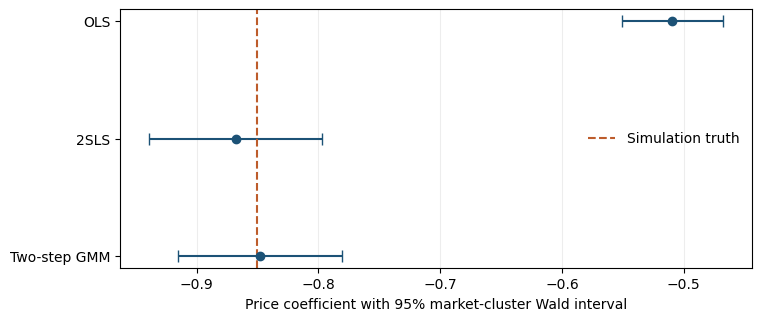

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.1), constrained_layout=True)
locations = np.arange(len(labels))
estimates = np.array([model["theta"][2] for model in fitted_models])
standard_errors = np.array([model["se"][2] for model in fitted_models])
ax.errorbar(estimates, locations, xerr=1.96 * standard_errors,
            fmt="o", capsize=4, color="#1c5276")
ax.axvline(true_theta[2], color="#bd5c2b", linestyle="--", label="Simulation truth")
ax.set_yticks(locations, labels)
ax.invert_yaxis()
ax.set_xlabel("Price coefficient with 95% market-cluster Wald interval")
ax.grid(axis="x", alpha=0.22)
ax.legend(loc="center right", frameon=False)
plt.show()

图中点为各方法的价格系数，横线按各自标准误计算，虚线为模拟真值。OLS 的区间描述其拟合系数的抽样波动。价格内生时，OLS 估计所趋近的系数可能偏离真实需求参数，本例的窄区间离真值仍很远。

内生性会直接影响经济结论。保持其他产品价格不变时，简单 Logit 的自价格弹性为 $\beta_p p_{jt}(1-s_{jt})$。因此价格系数偏向零的估计也会低估本例中自价格弹性的绝对值。有限样本中，GMM 和 2SLS 离真值的距离会随样本改变。两步 GMM 的渐近效率结论以工具变量和权重估计条件成立为前提。

**Hansen $J$ 检验。** 有效的聚类权重给出 $J=N g_N(\hat\theta_2)'W_2g_N(\hat\theta_2)$。若矩条件正确、识别足够强且市场数趋大，$J$ 的极限分布为 $\chi^2_{L-K}$。过度识别检验针对所用矩条件能否被同一参数同时满足，拒绝后仍需找出原因。当两个工具共同失效或检验功效不足时，未拒绝的情况也可能出现。

## 5. 改变工具的有效性和强度

在所有情形固定随机种子。先令 $z_2$ 同时进入 $\xi$，模拟成本冲击直接改变消费者感知品质，保留 $z_1$ 的有效性。再恢复排除限制，把两个成本工具到价格的传导同时缩小。并列看价格系数、过度识别检验与第一阶段。

在弱工具的情景中仍计算同样的点估计作为对照。这个情景只展示相关性变弱时的估计变化，常规 Wald 区间和 $J$ 检验的渐近近似依赖强识别。

In [5]:
invalid = simulate_markets(direct_cost_effect=0.45)
weak = simulate_markets(cost_strength=0.035)

print("Scenario                  First-stage R²    2SLS price    GMM price     J p-value")
for name, data in [("Valid baseline", base), ("Invalid z2", invalid), ("Weak cost shifts", weak)]:
    _, result1, result2 = estimate_demand(data)
    _, partial, _, _ = first_stage(data)
    degrees = data["Z"].shape[1] - data["X"].shape[1]
    p_value = chi2.sf(result2["criterion"], degrees)
    reported_p = f"{p_value:10.3g}" if name != "Weak cost shifts" else "        —"
    print(f"{name:24} {partial:13.4f} {result1['theta'][2]:13.4f} "
          f"{result2['theta'][2]:12.4f} {reported_p}")

z1_only = dict(invalid, Z=invalid["Z"][:, :3])
_, one_valid, _ = estimate_demand(z1_only)
print(f"\nInvalid-z2 design, dropping z2: 2SLS price = {one_valid['theta'][2]:.4f}")

Scenario                  First-stage R²    2SLS price    GMM price     J p-value
Valid baseline                  0.6328       -0.8679      -0.8480     0.0452
Invalid z2                      0.7307       -0.5514      -0.5019   1.49e-20
Weak cost shifts                0.0067       -0.2121      -0.1877         —

Invalid-z2 design, dropping z2: 2SLS price = -0.9625


在种子 607 的基准样本里，$J$ 检验的 $p$ 值为 0.045。尽管两个工具按模拟设定都有效，按 5% 水平仍会拒绝。改用种子 0 至 199，基准情形有 9 次在 5% 水平拒绝，无效工具情形则有 200 次拒绝。这两项频率来自指定的模拟设计和有限次重复。弱传导情形的第一阶段部分 $R^2$ 很小，此处只汇报点估计。

在无效工具情形只保留有效的 $z_1$ 后，点估计仍随样本变化。此时 $L=K$，恰好识别，因而没有剩余矩条件可用于过度识别检验。

## 课后练习

1. **从反演到弹性。** 逐步推出 $s_j/s_0=\exp(\delta_j)$、$\partial s_j/\partial p_j$ 与 $\partial s_k/\partial p_j$。选择一个市场，用有限差分核对这两个导数。保留 $\hat\xi=\log(s_j/s_0)-X\hat\theta$，改变一款产品的价格，比较 OLS 和 GMM 对其他产品份额的预测。交一份含导数、最大差分误差和反事实图的 Notebook。
2. **从投影到矩条件。** 用矩阵代数证明权重为 $(Z'Z/N)^{-1}$ 时线性 GMM 等于 2SLS。只保留一个被排除的工具，分别用两组正定权重求解。用 $L=K$ 和满秩条件解释为什么点估计相同，并检查样本矩进入什么数量级。
3. **聚类推断。** 固定 2SLS 的点估计和权重，把矩协方差改为逐行外积之和，再与市场聚类结果比较。分别把模拟式中 $\eta_t$ 的系数从 0.55 改为 0 和 1.10，各跑至少 100 个固定种子。报告截距和价格系数在两种区间下的覆盖率和相应蒙特卡洛标准误，解释哪种条件下会拉开差距。
4. **弱工具和无效工具。** 在至少 100 个固定种子上比较基准、弱传导和无效工具情景。报告部分 $R^2$、价格系数分布的中位数和四分位距。在基准和无效工具情形统计 5% 水平下的 $J$ 检验拒绝率。再分别只保留 $z_1$ 和 $z_2$，比较点估计和剩余的可检验限制。用一段话说明，若这些成本变量来自现实业务，还要找什么制度证据才能为排除限制辩护。

下一步把产品按类别分组，让同组产品互相替代得更紧密。在嵌套 Logit 中，组内份额也会成为需要识别的右侧变量。 [第 7 课](07-nested-logit.ipynb)